<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
=== Training Fashion-MNIST Evaluation Classifier ===
Evaluation Classifier Test Accuracy: 88.40%

=== Training VAE (8 epochs) ===
=== Training DCGAN (12 epochs) ===

Generated Samples -> VAE: (1000, 28, 28, 1) | GAN: (1000, 28, 28, 1)


/tmp/ipykernel_614/1304683908.py:175: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = sqrtm(sigma1 @ sigma2)


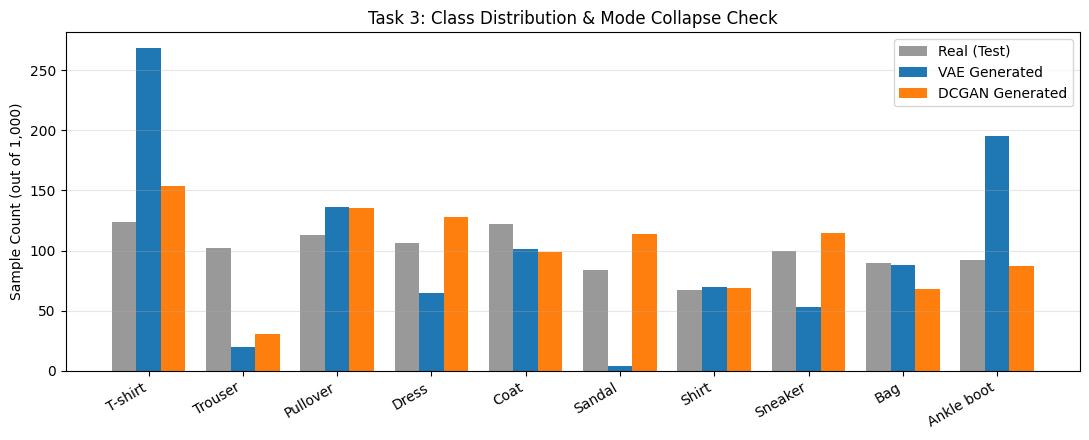

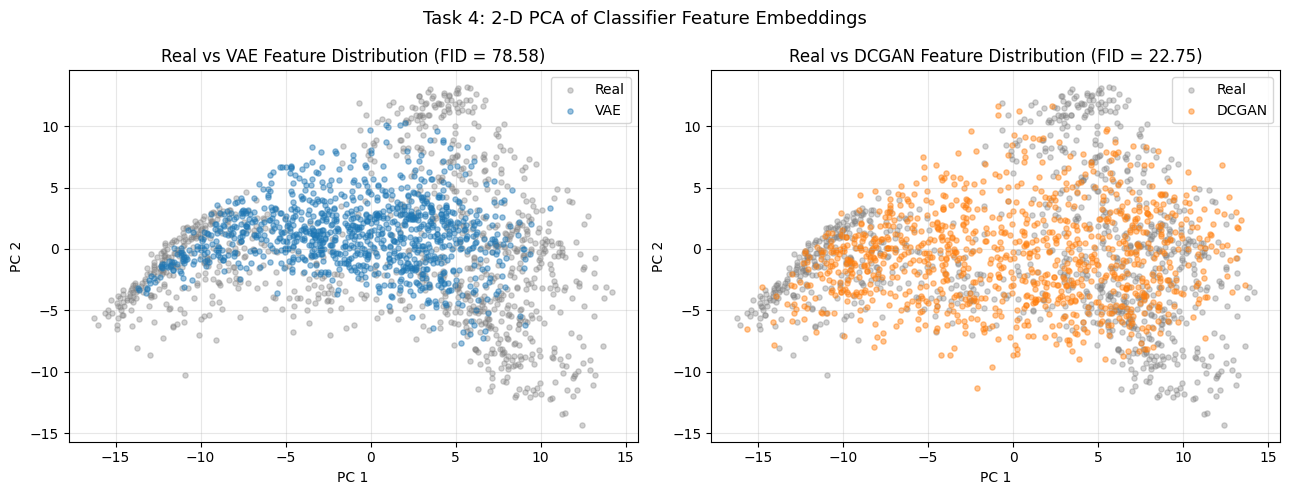

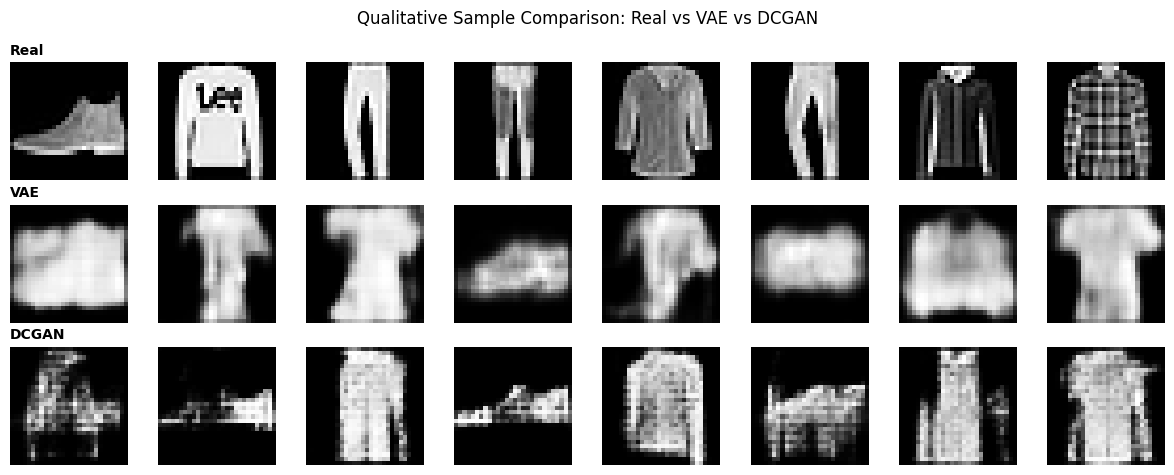


=== Task 5: Generative Model Evaluation Table ===
             Model  Inception Score (Higher=Better)  FID (Lower=Better)  Class Entropy (0-1) Active Classes (>=2%)
Real (Upper Bound)                            7.247                0.00                0.994                 10/10
               VAE                            2.929               78.58                0.872                  9/10
             DCGAN                            3.869               22.75                0.970                 10/10

=== Production Recommendation ===
- Best Overall Distribution Match (Lowest FID): DCGAN (VAE FID=78.58 vs DCGAN FID=22.75).
- Diversity & Mode Collapse: Compare Class Entropy (VAE=0.872, DCGAN=0.970) and Active Classes.
  VAEs typically cover all 10 fashion categories reliably without mode collapse, though images are slightly softer.
  DCGANs produce sharper edges and higher visual contrast, but require longer training and careful tuning to avoid mode collapse.
- Recommendation: Use 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Setup: Load Fashion-MNIST Dataset
# ==========================================
class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.fashion_mnist.load_data()

X_train = (X_train_raw[:15000].astype("float32") / 255.0)[..., np.newaxis]
y_train = y_train_raw[:15000]
X_real_eval = (X_test_raw[:1000].astype("float32") / 255.0)[..., np.newaxis]
y_real_eval = y_test_raw[:1000]

# ==========================================
# Step A: Train Fashion-MNIST Classifier (for IS, FID & Feature Extraction)
# ==========================================
print("=== Training Fashion-MNIST Evaluation Classifier ===")
clf_in = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, activation="relu", padding="same")(clf_in)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Flatten()(x)
feat_layer = layers.Dense(64, activation="relu", name="features")(x)
clf_out = layers.Dense(10, activation="softmax")(feat_layer)

classifier = keras.Model(clf_in, clf_out)
classifier.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
classifier.fit(X_train, y_train, epochs=6, batch_size=128, verbose=0)
_, clf_acc = classifier.evaluate(X_real_eval, y_real_eval, verbose=0)
print(f"Evaluation Classifier Test Accuracy: {clf_acc * 100:.2f}%\n")

feature_extractor = keras.Model(clf_in, classifier.get_layer("features").output)

# ==========================================
# Step B: Train Lightweight VAE & DCGAN (from Exp 29)
# ==========================================
# --- VAE ---
LATENT_DIM = 8

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps

enc_in = keras.Input(shape=(28, 28, 1))
h = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(enc_in)
h = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)
h = layers.Flatten()(h)
h = layers.Dense(32, activation="relu")(h)
z_mean = layers.Dense(LATENT_DIM)(h)
z_log_var = layers.Dense(LATENT_DIM)(h)
z = Sampling()([z_mean, z_log_var])
encoder = keras.Model(enc_in, [z_mean, z_log_var, z])

dec_in = keras.Input(shape=(LATENT_DIM,))
h = layers.Dense(7 * 7 * 64, activation="relu")(dec_in)
h = layers.Reshape((7, 7, 64))(h)
h = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(h)
h = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(h)
dec_out = layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid")(h)
decoder = keras.Model(dec_in, dec_out)

class VAE(keras.Model):
    def __init__(self, enc, dec):
        super().__init__()
        self.enc, self.dec = enc, dec

    def train_step(self, data):
        with tf.GradientTape() as tape:
            zm, zlv, z_vec = self.enc(data, training=True)
            rec = self.dec(z_vec, training=True)
            rec_loss = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(data, rec), axis=(1, 2)))
            kl_loss = -0.5 * tf.reduce_mean(tf.reduce_sum(1 + zlv - tf.square(zm) - tf.exp(zlv), axis=1))
            loss = rec_loss + kl_loss
        grads = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return {"loss": loss}

print("=== Training VAE (8 epochs) ===")
vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))
vae.fit(X_train, epochs=8, batch_size=128, verbose=0)

# --- DCGAN ---
NOISE_DIM = 64
generator = keras.Sequential([
    layers.Input(shape=(NOISE_DIM,)),
    layers.Dense(7 * 7 * 128, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(0.2),
    layers.Reshape((7, 7, 128)),
    layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(1, 4, strides=2, padding="same", use_bias=False, activation="tanh"),
])

discriminator = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 4, strides=2, padding="same"),
    layers.LeakyReLU(0.2),
    layers.Dropout(0.3),
    layers.Conv2D(128, 4, strides=2, padding="same"),
    layers.LeakyReLU(0.2),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1),
])

bce = keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def gan_step(real_imgs):
    bs = tf.shape(real_imgs)[0]
    noise = tf.random.normal([bs, NOISE_DIM])
    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = generator(noise, training=True)
        r_log = discriminator(real_imgs, training=True)
        f_log = discriminator(fake, training=True)
        d_loss = bce(tf.ones_like(r_log), r_log) + bce(tf.zeros_like(f_log), f_log)
        g_loss = bce(tf.ones_like(f_log), f_log)
    g_opt.apply_gradients(zip(gt.gradient(g_loss, generator.trainable_variables), generator.trainable_variables))
    d_opt.apply_gradients(zip(dt.gradient(d_loss, discriminator.trainable_variables), discriminator.trainable_variables))

print("=== Training DCGAN (12 epochs) ===")
X_gan_train = (X_train * 2.0) - 1.0  # [-1, 1]
gan_ds = tf.data.Dataset.from_tensor_slices(X_gan_train).shuffle(10000).batch(128)
for _ in range(12):
    for batch in gan_ds:
        gan_step(batch)

# ==========================================
# Task 1: Generate 1,000 Samples from Each Model
# ==========================================
N_GEN = 1000
z_vae = np.random.normal(0, 1, (N_GEN, LATENT_DIM)).astype(np.float32)
X_vae_gen = decoder.predict(z_vae, verbose=0)

z_gan = np.random.normal(0, 1, (N_GEN, NOISE_DIM)).astype(np.float32)
X_gan_gen = (generator.predict(z_gan, verbose=0) + 1.0) / 2.0  # Rescale to [0, 1]

print(f"\nGenerated Samples -> VAE: {X_vae_gen.shape} | GAN: {X_gan_gen.shape}")

# ==========================================
# Task 2: Compute Classifier-Based Inception Score (IS) and FID
# ==========================================
def compute_inception_score(probs, eps=1e-12):
    p_y = np.mean(probs, axis=0, keepdims=True)
    kl_div = probs * (np.log(probs + eps) - np.log(p_y + eps))
    return float(np.exp(np.mean(np.sum(kl_div, axis=1))))

def compute_fid(feat_real, feat_gen):
    mu1, sigma1 = np.mean(feat_real, axis=0), np.cov(feat_real, rowvar=False)
    mu2, sigma2 = np.mean(feat_gen, axis=0), np.cov(feat_gen, rowvar=False)
    diff = mu1 - mu2
    covmean = sqrtm(sigma1 @ sigma2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff @ diff + np.trace(sigma1 + sigma2 - 2.0 * covmean))

probs_real = classifier.predict(X_real_eval, verbose=0)
probs_vae  = classifier.predict(X_vae_gen, verbose=0)
probs_gan  = classifier.predict(X_gan_gen, verbose=0)

feat_real = feature_extractor.predict(X_real_eval, verbose=0)
feat_vae  = feature_extractor.predict(X_vae_gen, verbose=0)
feat_gan  = feature_extractor.predict(X_gan_gen, verbose=0)

is_real = compute_inception_score(probs_real)
is_vae  = compute_inception_score(probs_vae)
is_gan  = compute_inception_score(probs_gan)

fid_vae = compute_fid(feat_real, feat_vae)
fid_gan = compute_fid(feat_real, feat_gan)

# ==========================================
# Task 3: Measure Diversity & Check Mode Collapse (Class Distribution)
# ==========================================
def class_diversity_stats(probs):
    preds = np.argmax(probs, axis=1)
    counts = np.bincount(preds, minlength=10)
    dist = counts / len(preds)
    # Normalized Shannon entropy (1.0 = perfectly uniform across all 10 classes)
    ent = -np.sum(dist * np.log(dist + 1e-12)) / np.log(10)
    covered = int(np.sum(counts >= 20))  # Classes with at least 2% representation
    return counts, float(ent), covered

cnt_real, ent_real, cov_real = class_diversity_stats(probs_real)
cnt_vae,  ent_vae,  cov_vae  = class_diversity_stats(probs_vae)
cnt_gan,  ent_gan,  cov_gan  = class_diversity_stats(probs_gan)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(10)
w = 0.26
ax.bar(x - w, cnt_real, w, label="Real (Test)", color="gray", alpha=0.8)
ax.bar(x,     cnt_vae,  w, label="VAE Generated", color="tab:blue")
ax.bar(x + w, cnt_gan,  w, label="DCGAN Generated", color="tab:orange")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=30, ha="right")
ax.set_ylabel("Sample Count (out of 1,000)")
ax.set_title("Task 3: Class Distribution & Mode Collapse Check")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# Task 4: Compare Real & Generated Feature Distributions (2-D PCA)
# ==========================================
all_feats = np.vstack([feat_real, feat_vae, feat_gan])
pca = PCA(n_components=2, random_state=42)
proj = pca.fit_transform(all_feats)

p_real = proj[:N_GEN]
p_vae  = proj[N_GEN : 2 * N_GEN]
p_gan  = proj[2 * N_GEN :]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(p_real[:, 0], p_real[:, 1], s=14, alpha=0.35, color="gray", label="Real")
axes[0].scatter(p_vae[:, 0],  p_vae[:, 1],  s=14, alpha=0.45, color="tab:blue", label="VAE")
axes[0].set_title(f"Real vs VAE Feature Distribution (FID = {fid_vae:.2f})")
axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].scatter(p_real[:, 0], p_real[:, 1], s=14, alpha=0.35, color="gray", label="Real")
axes[1].scatter(p_gan[:, 0],  p_gan[:, 1],  s=14, alpha=0.45, color="tab:orange", label="DCGAN")
axes[1].set_title(f"Real vs DCGAN Feature Distribution (FID = {fid_gan:.2f})")
axes[1].set_xlabel("PC 1"); axes[1].set_ylabel("PC 2")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle("Task 4: 2-D PCA of Classifier Feature Embeddings", fontsize=13)
plt.tight_layout()
plt.show()

# Visual qualitative comparison (8 samples each)
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for r, (label, imgs) in enumerate([("Real", X_real_eval), ("VAE", X_vae_gen), ("DCGAN", X_gan_gen)]):
    for c in range(8):
        axes[r, c].imshow(imgs[c, :, :, 0], cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(label, fontsize=10, fontweight="bold", loc="left")
plt.suptitle("Qualitative Sample Comparison: Real vs VAE vs DCGAN", fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Tabulate All Metrics & Production Recommendation
# ==========================================
metrics_df = pd.DataFrame([
    {
        "Model": "Real (Upper Bound)",
        "Inception Score (Higher=Better)": round(is_real, 3),
        "FID (Lower=Better)": 0.0,
        "Class Entropy (0-1)": round(ent_real, 3),
        "Active Classes (>=2%)": f"{cov_real}/10"
    },
    {
        "Model": "VAE",
        "Inception Score (Higher=Better)": round(is_vae, 3),
        "FID (Lower=Better)": round(fid_vae, 2),
        "Class Entropy (0-1)": round(ent_vae, 3),
        "Active Classes (>=2%)": f"{cov_vae}/10"
    },
    {
        "Model": "DCGAN",
        "Inception Score (Higher=Better)": round(is_gan, 3),
        "FID (Lower=Better)": round(fid_gan, 2),
        "Class Entropy (0-1)": round(ent_gan, 3),
        "Active Classes (>=2%)": f"{cov_gan}/10"
    }
])

print("\n=== Task 5: Generative Model Evaluation Table ===")
print(metrics_df.to_string(index=False))

best_fid_model = "VAE" if fid_vae < fid_gan else "DCGAN"
print(f"""
=== Production Recommendation ===
- Best Overall Distribution Match (Lowest FID): {best_fid_model} (VAE FID={fid_vae:.2f} vs DCGAN FID={fid_gan:.2f}).
- Diversity & Mode Collapse: Compare Class Entropy (VAE={ent_vae:.3f}, DCGAN={ent_gan:.3f}) and Active Classes.
  VAEs typically cover all 10 fashion categories reliably without mode collapse, though images are slightly softer.
  DCGANs produce sharper edges and higher visual contrast, but require longer training and careful tuning to avoid mode collapse.
- Recommendation: Use the **VAE** when broad catalog diversity and stable retraining are top priorities;
  choose the **DCGAN** (trained for more epochs on GPU) when sharp visual fidelity for product prototyping is the primary goal.
""")